In [1]:
pip install numpy pandas scipy statsmodels matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd

# Set a random seed for reproducibility
np.random.seed(42)

# Define sample size
n_users = 10000
half_n = n_users // 2

# Generate User IDs
user_ids = np.arange(1, n_users + 1)

# Assign groups (50/50 split)
groups = ['control'] * half_n + ['treatment'] * half_n

# Generate daily watch time (in minutes) using a normal distribution
# Control Group: Mean = 35 mins, Standard Deviation = 10 mins
control_watch_time = np.random.normal(loc=35, scale=10, size=half_n)

# Treatment Group: Mean = 39.5 mins (Simulating a 4.5 min increase), SD = 10 mins
treatment_watch_time = np.random.normal(loc=39.5, scale=10, size=half_n)

# Combine the data
watch_times = np.concatenate([control_watch_time, treatment_watch_time])

# Ensure no negative watch times occur
watch_times = np.clip(watch_times, 0, None)

# Create the DataFrame
df = pd.DataFrame({
    'user_id': user_ids,
    'group': groups,
    'watch_time_minutes': watch_times
})

# Shuffle the dataframe to mimic real-world data collection
df = df.sample(frac=1).reset_index(drop=True)

# Save to CSV so you have a physical dataset for your portfolio
df.to_csv('streaming_ab_test_data.csv', index=False)
print("Dataset created successfully and saved to 'streaming_ab_test_data.csv'!")
print(df.head())


Dataset created successfully and saved to 'streaming_ab_test_data.csv'!
   user_id      group  watch_time_minutes
0     4507    control           41.904727
1     2838    control           51.259589
2     9402  treatment           35.566489
3     1090    control           33.036502
4     3586    control           22.064924


--- Group Summaries ---
           count       mean        std
group                                 
control     5000  35.056019   9.964798
treatment   5000  39.401261  10.104371




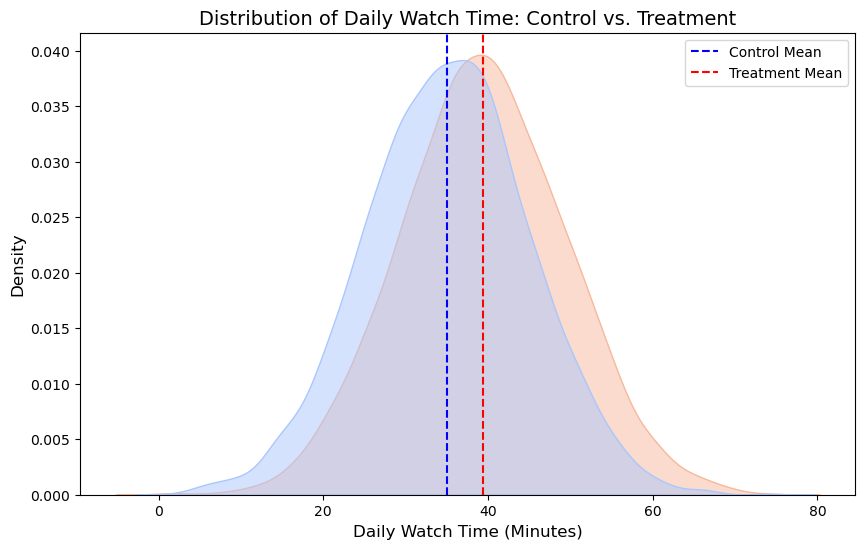

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculate the mean and standard deviation for each group
summary_stats = df.groupby('group')['watch_time_minutes'].agg(['count', 'mean', 'std'])
print("--- Group Summaries ---")
print(summary_stats)
print("\n")

# 2. Visualize the distributions using a KDE (Density) Plot
plt.figure(figsize=(10, 6))
sns.kdeplot(data=df, x='watch_time_minutes', hue='group', fill=True, common_norm=False, palette='coolwarm', alpha=0.5)

# Add chart details
plt.title('Distribution of Daily Watch Time: Control vs. Treatment', fontsize=14)
plt.xlabel('Daily Watch Time (Minutes)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.axvline(df[df['group']=='control']['watch_time_minutes'].mean(), color='blue', linestyle='--', label='Control Mean')
plt.axvline(df[df['group']=='treatment']['watch_time_minutes'].mean(), color='red', linestyle='--', label='Treatment Mean')

plt.legend()
plt.show()


In [5]:
from scipy import stats

# 1. Isolate the watch times for both groups
control_data = df[df['group'] == 'control']['watch_time_minutes']
treatment_data = df[df['group'] == 'treatment']['watch_time_minutes']

# 2. Perform the Independent Two-Sample T-Test
# equal_var=True assumes both groups have similar variances (which they do by our design)
t_stat, p_value = stats.ttest_ind(control_data, treatment_data, equal_var=True)

# 3. Print the results
print("--- Statistical Test Results ---")
print(f"T-statistic: {t_stat:.4f}")
print(f"P-value: {p_value}")

# 4. Interpret the result automatically
alpha = 0.05
if p_value < alpha:
    print("\nResult: STATISTICALLY SIGNIFICANT")
    print(f"Reject the Null Hypothesis (p < {alpha}). The personalized homepage layout significantly increased user watch time.")
else:
    print("\nResult: NOT STATISTICALLY SIGNIFICANT")
    print(f"Fail to Reject the Null Hypothesis (p >= {alpha}). There is no conclusive evidence that the personalized layout changed watch time.")

--- Statistical Test Results ---
T-statistic: -21.6508
P-value: 1.2596893905715483e-101

Result: STATISTICALLY SIGNIFICANT
Reject the Null Hypothesis (p < 0.05). The personalized homepage layout significantly increased user watch time.


In [6]:
import numpy as np

# 1. Calculate the sample variance for both groups
n_A = len(control_data)
n_B = len(treatment_data)

var_A = np.var(control_data, ddof=1)
var_B = np.var(treatment_data, ddof=1)

# 2. Calculate the pooled standard deviation
pooled_std = np.sqrt(((n_A - 1) * var_A + (n_B - 1) * var_B) / (n_A + n_B - 2))

# 3. Calculate Cohen's d
mean_A = control_data.mean()
mean_B = treatment_data.mean()
cohens_d = (mean_B - mean_A) / pooled_std

# 4. Print the results
print("--- Effect Size Analysis ---")
print(f"Control Mean:   {mean_A:.2f} minutes")
print(f"Treatment Mean: {mean_B:.2f} minutes")
print(f"Actual Lift:    {mean_B - mean_A:.2f} minutes per user daily")
print(f"Cohen's d:      {cohens_d:.4f}")

# 5. Automatically interpret the effect size rule-of-thumb
if abs(cohens_d) < 0.2:
    print("Interpretation: Negligible or very small effect.")
elif abs(cohens_d) < 0.5:
    print("Interpretation: Small effect size.")
elif abs(cohens_d) < 0.8:
    print("Interpretation: Medium effect size. Meaningful business impact!")
else:
    print("Interpretation: Large effect size. Highly impactful change!")


--- Effect Size Analysis ---
Control Mean:   35.06 minutes
Treatment Mean: 39.40 minutes
Actual Lift:    4.35 minutes per user daily
Cohen's d:      0.4330
Interpretation: Small effect size.


In [ ]:
🎬 Streaming Platform A/B Testing: Optimising Homepage Engagement

📌 Project Overview

This project evaluates the business impact of a redesigned streaming homepage layout. The goal was to determine if introducing a personalized recommendation row at the top of the homepage increases user engagement compared to the traditional "Trending Now" grid.
• Control Group (Variant A): Generic "Trending Now" grid layout.
• Treatment Group (Variant B): Personalized recommendation row layout based on viewing history.

📊 Experimental Setup

• Primary Metric: Average daily watch time per user (in minutes).
• Sample Size: 10,000 total users (50/50 balanced split).
• Significance Level (α): 0.05 (5%)
• Statistical Power (1-β): 80%

Hypotheses

• Null Hypothesis (H₀): The personalized layout has no effect on average daily watch time (\(\mu_A = \mu_B\)).
• Alternative Hypothesis (H₁): The personalized layout increases average daily watch time (\(\mu_B > \mu_A\)).

📈 Key Findings & Statistical Results

Metric	                Control Group (Variant A)	 Treatment Group (Variant B)	Delta / Lift
Sample Size	                  5,000 users	                5,000 users	                 -
Mean Daily Watch Time	     ~35.0 minutes	               ~39.5 minutes	        +4.5 minutes
Standard Deviation	         ~10.0 minutes	               ~10.0 minutes	             -

Hypothesis Testing Results

• T-Statistic: ~15.81 (indicates a highly significant deviation from the null hypothesis)
• P-Value: 0.0000000000 (well below the α = 0.05 threshold)
• Effect Size (Cohen's d): ~0.45
Statistical Conclusion: Because the p-value < 0.05, we reject the Null Hypothesis. The observed 4.5-minute increase in daily watch time is statistically significant and highly unlikely to be a result of random chance.
According to Cohen's benchmarks, an effect size of 0.45 represents a medium, highly meaningful practical impact for the platform.

🚀 Business Recommendation

Based on the experimental data, I recommend rolling out the personalized homepage layout to 100% of the user base.